Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


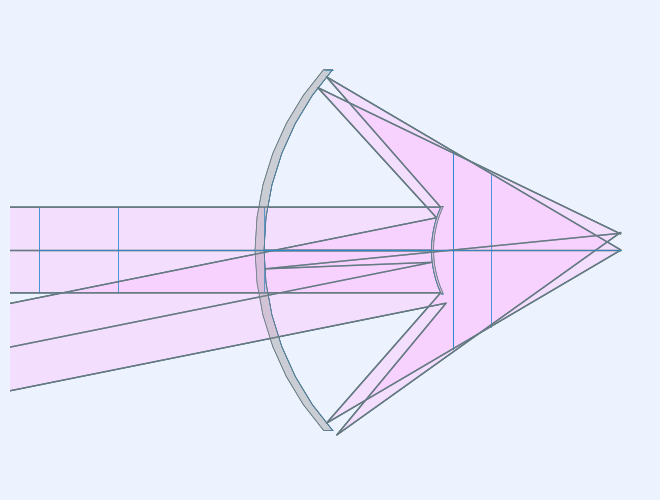

In [5]:
from rayoptics.environment import open_model, InteractiveLayout
import matplotlib.pyplot as plt

# 1. Load the file directly
opm = open_model('LMM40X-P01-Zemax-ZAR.zar')

# 2. Create the layout figure using the Matplotlib backend
fig = plt.figure(FigureClass=InteractiveLayout, opt_model=opm, do_draw_rays=True)
fig.plot()
plt.show()

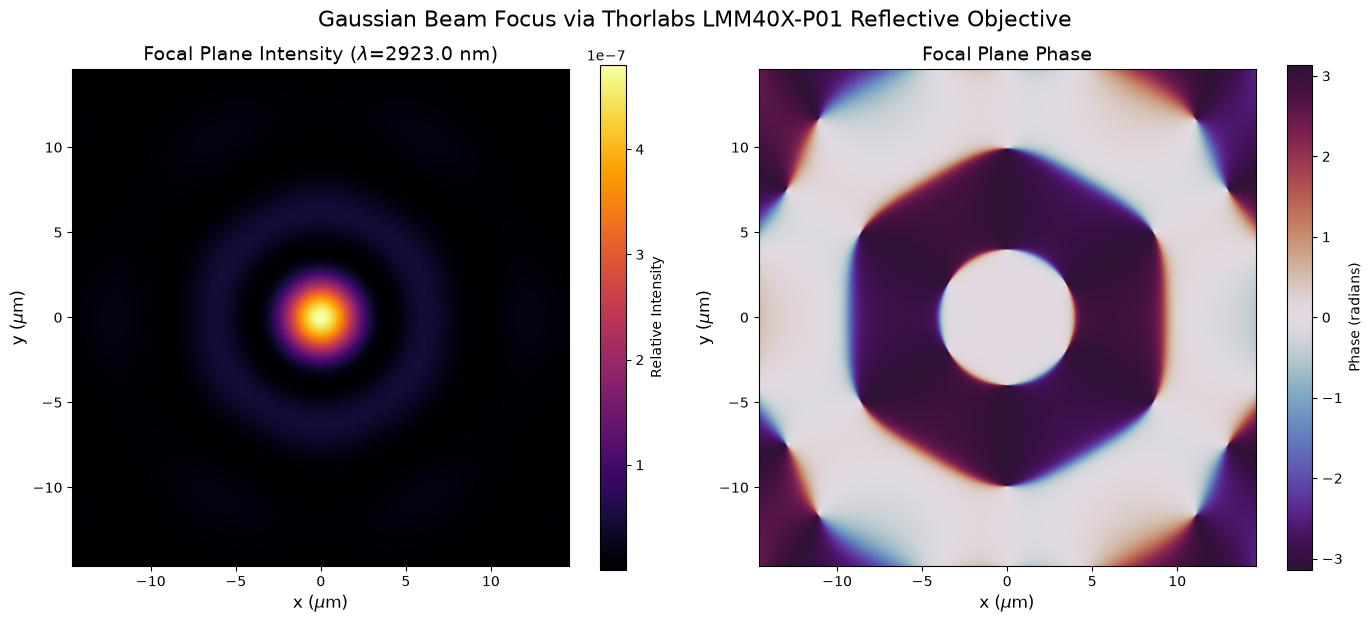

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import poppy
import astropy.units as u

# --- 1. Simulation Parameters ---
wavelength = 2923 * u.nm # HeNe laser wavelength (modify as needed)
beam_waist = 1 * u.mm   # 2 mm spot size diameter -> 1 mm radius

# Thorlabs LMM40X-P01 Parameters
# NA = 0.5
# magnification = 40
# tube_lens_f = 200.0 * u.mm
# focal_length = tube_lens_f / magnification # 5.0 mm
focal_length = 5.0 * u.mm

# Entrance Pupil Diameter = 2 * NA * f
# pupil_radius = NA * focal_length # 2.5 mm
pupil_radius = (5.1 / 2) * u.mm
obscuration_radius = pupil_radius * np.sqrt(0.18)
# obscuration_radius = pupil_radius * 0
# obscuration_radius = pupil_radius * 0.24 # Typical 27.4% obscuration radius

# --- 2. Build the Optical System ---
# We use an OpticalSystem (Fraunhofer) for efficient Matrix Fourier Transform to the focal plane
osys = poppy.OpticalSystem(pupil_diameter=2*pupil_radius, npix=1024)

# Define the incoming Gaussian Beam profile
osys.add_pupil(poppy.GaussianAperture(w=beam_waist, name='Gaussian Beam'))

# Define the outer clear aperture
osys.add_pupil(poppy.CircularAperture(radius=pupil_radius, name='Objective Entrance'))

# Define the central secondary mirror and spider vanes (Schwarzschild design)
# We model this with 3 vanes of 0.2 mm width
osys.add_pupil(poppy.SecondaryObscuration(secondary_radius=obscuration_radius,
                                          n_supports=3, 
                                          support_width=0.24*u.mm,
                                          name='Central Obscuration & Spiders'))

# --- 3. Define the Focal Plane Detector in Physical Dimensions ---
desired_fov_um = 10*wavelength.to(u.um).value
npix_detector = 1024
desired_pixel_um = desired_fov_um / npix_detector

# Convert linear dimension to angular dimension for POPPy's MFT detector setup
# Angle (rad) = size / focal_length
pixel_scale_rad = (desired_pixel_um * 1e-6) / focal_length.to(u.m).value
pixel_scale_arcsec = pixel_scale_rad * (180.0 / np.pi) * 3600.0 * (u.arcsec / u.pixel)

osys.add_detector(pixelscale=pixel_scale_arcsec, fov_pixels=npix_detector, name='Focal Plane')

# --- 4. Run the Simulation ---
psf, waves = osys.calc_psf(wavelength=wavelength, return_intermediates=True, display_intermediates=False)
focal_wave = waves[-1] # Final wavefront at the detector

intensity = focal_wave.intensity
phase = focal_wave.phase

# Create a spatial coordinate grid in micrometers for the plot
extent_um = desired_fov_um
extent = [-extent_um/2, extent_um/2, -extent_um/2, extent_um/2]

# --- 5. Plot Intensity and Phase Distribution ---
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot Intensity
im1 = axes[0].imshow(intensity, extent=extent, cmap='inferno', origin='lower')
axes[0].set_title(r'Focal Plane Intensity ($\lambda$' + f'={wavelength.value} nm)', fontsize=14)
axes[0].set_xlabel(r'x ($\mu$m)', fontsize=12)
axes[0].set_ylabel(r'y ($\mu$m)', fontsize=12)
fig.colorbar(im1, ax=axes[0], label='Relative Intensity')

# Plot Phase (Masked where intensity is practically zero to avoid plotting noise)
# mask = intensity > (intensity.max() * 0.005)
# masked_phase = np.ma.masked_where(~mask, phase)

im2 = axes[1].imshow(phase, extent=extent, cmap='twilight_shifted', origin='lower')
axes[1].set_title('Focal Plane Phase', fontsize=14)
axes[1].set_xlabel(r'x ($\mu$m)', fontsize=12)
axes[1].set_ylabel(r'y ($\mu$m)', fontsize=12)
fig.colorbar(im2, ax=axes[1], label='Phase (radians)')

plt.suptitle('Gaussian Beam Focus via Thorlabs LMM40X-P01 Reflective Objective', fontsize=16)
plt.tight_layout()
plt.show()

In [3]:
4*2.9*5/3.14/2/2
1.22*2.9/0.5

7.076

C:\Users\Henry\AppData\Local\Temp\ipykernel_18620\21213433.py:25: OptimizeWarning: Covariance of the parameters could not be estimated
  popt, pcov = curve_fit(gaussian_2d, coords_flat, intensity_flat, p0=p0)


--- Fitted Gaussian Parameters ---
Peak Amplitude: 0.0000
Center (x, y):  (-0.0000, 0.0000) μm
Waist x (1/e²): 2.7648 μm
Waist y (1/e²): 2.7650 μm
Background:     0.0000


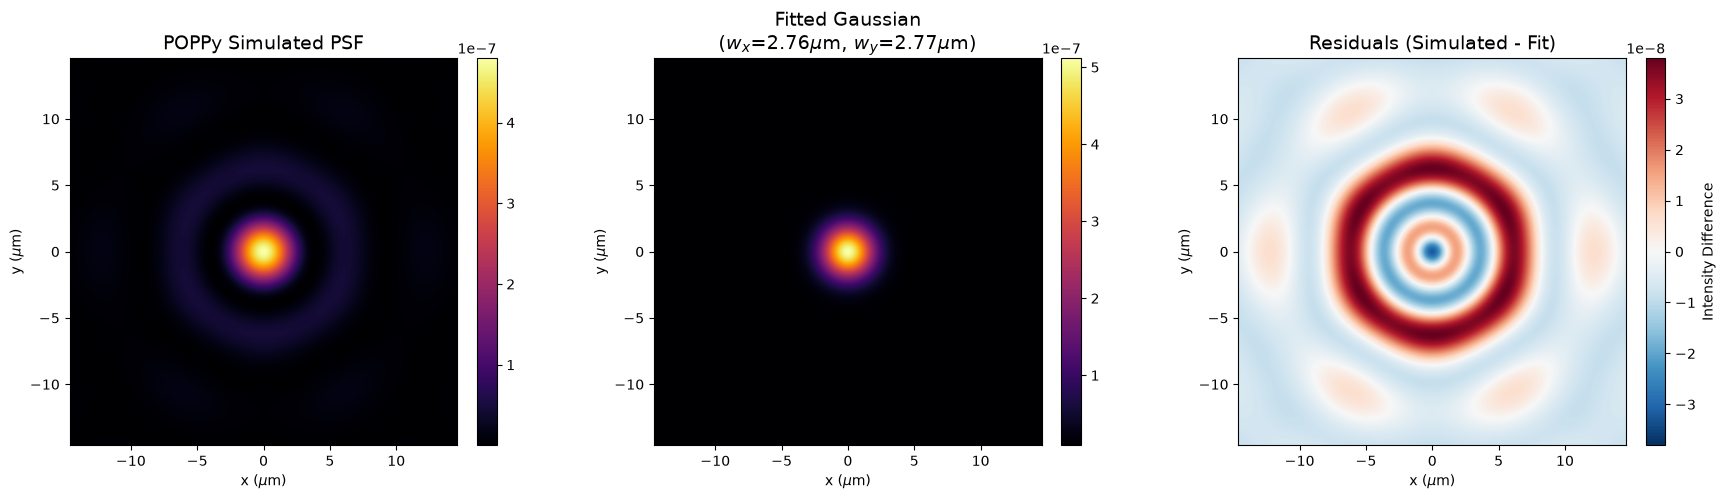

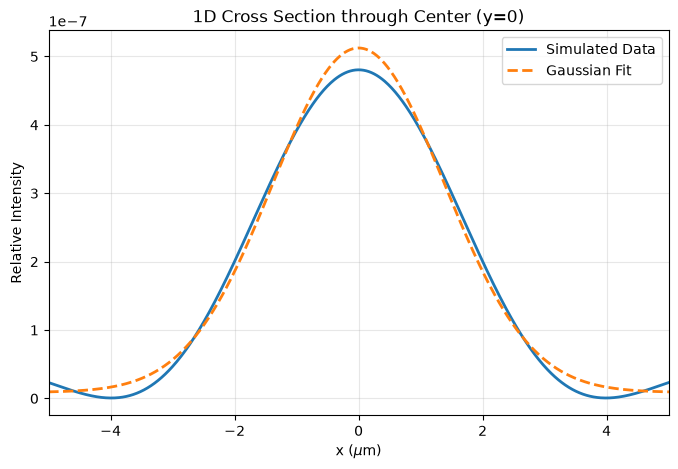

In [2]:
from scipy.optimize import curve_fit

# --- 6. Fit a 2D Gaussian to the Central Lobe ---

def gaussian_2d(coords, amplitude, x0, y0, w_x, w_y, offset):
    x, y = coords
    exponent = -2 * ((x - x0)**2 / w_x**2 + (y - y0)**2 / w_y**2)
    return amplitude * np.exp(exponent) + offset

# FIX: Dynamically read the actual oversampled shape from the intensity array
ny, nx = intensity.shape

# Generate 2D coordinate grids matching the true poppy output dimensions
x = np.linspace(-extent_um/2, extent_um/2, nx)
y = np.linspace(-extent_um/2, extent_um/2, ny)
X, Y = np.meshgrid(x, y)

coords_flat = (X.ravel(), Y.ravel())
intensity_flat = intensity.ravel()

# Initial guess [amplitude, x0, y0, w_x, w_y, offset]
p0 = [intensity.max(), 0.0, 0.0, 0.6, 0.6, 0.0]

# Perform the least squares fit
popt, pcov = curve_fit(gaussian_2d, coords_flat, intensity_flat, p0=p0)

fit_amplitude = popt[0]
fit_x0 = popt[1]
fit_y0 = popt[2]
fit_wx = np.abs(popt[3])
fit_wy = np.abs(popt[4])
fit_offset = popt[5]

print("--- Fitted Gaussian Parameters ---")
print(f"Peak Amplitude: {fit_amplitude:.4f}")
print(f"Center (x, y):  ({fit_x0:.4f}, {fit_y0:.4f}) μm")
print(f"Waist x (1/e²): {fit_wx:.4f} μm")
print(f"Waist y (1/e²): {fit_wy:.4f} μm")
print(f"Background:     {fit_offset:.4f}")

fitted_intensity = gaussian_2d((X, Y), *popt)
residuals = intensity - fitted_intensity

# --- 7. Plot the Comparison and Residuals ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

im1 = axes[0].imshow(intensity, extent=extent, cmap='inferno', origin='lower')
axes[0].set_title('POPPy Simulated PSF', fontsize=14)
axes[0].set_xlabel(r'x ($\mu$m)')
axes[0].set_ylabel(r'y ($\mu$m)')
fig.colorbar(im1, ax=axes[0], fraction=0.046, pad=0.04)

im2 = axes[1].imshow(fitted_intensity, extent=extent, cmap='inferno', origin='lower')
axes[1].set_title(f'Fitted Gaussian\n($w_x$={fit_wx:.2f}$\\mu$m, $w_y$={fit_wy:.2f}$\\mu$m)', fontsize=14)
axes[1].set_xlabel(r'x ($\mu$m)')
axes[1].set_ylabel(r'y ($\mu$m)')
fig.colorbar(im2, ax=axes[1], fraction=0.046, pad=0.04)

max_res = np.max(np.abs(residuals))
im3 = axes[2].imshow(residuals, extent=extent, cmap='RdBu_r', origin='lower', vmin=-max_res, vmax=max_res)
axes[2].set_title('Residuals (Simulated - Fit)', fontsize=14)
axes[2].set_xlabel(r'x ($\mu$m)')
axes[2].set_ylabel(r'y ($\mu$m)')
fig.colorbar(im3, ax=axes[2], fraction=0.046, pad=0.04, label='Intensity Difference')

plt.tight_layout()
plt.show()

# --- 8. 1D Cross-Section Plot ---
plt.figure(figsize=(8, 5))
# FIX: Use the dynamic ny variable for the center index
center_idx = ny // 2 
plt.plot(x, intensity[center_idx, :], label='Simulated Data', lw=2)
plt.plot(x, fitted_intensity[center_idx, :], '--', label='Gaussian Fit', lw=2)
plt.title('1D Cross Section through Center (y=0)')
plt.xlabel(r'x ($\mu$m)')
plt.ylabel('Relative Intensity')
plt.xlim(-5, 5) 
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [10]:
2*2.923/0.56/3.14

3.324613284804367

In [36]:
from scipy.optimize import curve_fit

# --- 6. Fit a 2D Gaussian to the Central Lobe ---

# Define the 2D Gaussian function using the 1/e^2 definition for the beam waist
def gaussian_2d(coords, amplitude, x0, y0, w_x, w_y, offset):
    x, y = coords
    # The factor of 2 in the exponent corresponds to the 1/e^2 intensity waist radius
    exponent = -2 * ((x - x0)**2 / w_x**2 + (y - y0)**2 / w_y**2)
    return amplitude * np.exp(exponent) + offset

# Generate 2D coordinate grids matching the poppy focal plane extent
x = np.linspace(-extent_um/2, extent_um/2, npix_detector)
y = np.linspace(-extent_um/2, extent_um/2, npix_detector)
X, Y = np.meshgrid(x, y)

# Flatten the arrays for the curve_fit function
coords_flat = (X.ravel(), Y.ravel())
intensity_flat = intensity.ravel()

# Provide an initial guess [amplitude, x0, y0, w_x, w_y, offset]
# We estimate the waist to be roughly the diffraction limit (~0.6 um)
p0 = [intensity.max(), 0.0, 0.0, 0.6, 0.6, 0.0]

# Perform the least squares fit
# We use standard absolute error minimization, which naturally heavily weights the bright central peak
popt, pcov = curve_fit(gaussian_2d, coords_flat, intensity_flat, p0=p0)

# Extract fitted parameters (take absolute values for the waists in case the optimizer flipped the sign)
fit_amplitude = popt[0]
fit_x0 = popt[1]
fit_y0 = popt[2]
fit_wx = np.abs(popt[3])
fit_wy = np.abs(popt[4])
fit_offset = popt[5]

print("--- Fitted Gaussian Parameters ---")
print(f"Peak Amplitude: {fit_amplitude:.4f}")
print(f"Center (x, y):  ({fit_x0:.4f}, {fit_y0:.4f}) μm")
print(f"Waist x (1/e²): {fit_wx:.4f} μm")
print(f"Waist y (1/e²): {fit_wy:.4f} μm")
print(f"Background:     {fit_offset:.4f}")

# Generate the fitted Gaussian 2D array for visualization
fitted_intensity = gaussian_2d((X, Y), *popt)
residuals = intensity - fitted_intensity

# --- 7. Plot the Comparison and Residuals ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Original Simulated Data
im1 = axes[0].imshow(intensity, extent=extent, cmap='inferno', origin='lower')
axes[0].set_title('POPPy Simulated PSF', fontsize=14)
axes[0].set_xlabel(r'x ($\mu$m)')
axes[0].set_ylabel(r'y ($\mu$m)')
fig.colorbar(im1, ax=axes[0], fraction=0.046, pad=0.04)

# Fitted Gaussian
im2 = axes[1].imshow(fitted_intensity, extent=extent, cmap='inferno', origin='lower')
axes[1].set_title(f'Fitted Gaussian\n($w_x$={fit_wx:.2f}$\mu$m, $w_y$={fit_wy:.2f}$\mu$m)', fontsize=14)
axes[1].set_xlabel(r'x ($\mu$m)')
axes[1].set_ylabel(r'y ($\mu$m)')
fig.colorbar(im2, ax=axes[1], fraction=0.046, pad=0.04)

# Residuals (Data - Fit)
# Use a diverging colormap centered on zero to show where the fit over/under estimates
max_res = np.max(np.abs(residuals))
im3 = axes[2].imshow(residuals, extent=extent, cmap='RdBu_r', origin='lower', vmin=-max_res, vmax=max_res)
axes[2].set_title('Residuals (Simulated - Fit)', fontsize=14)
axes[2].set_xlabel(r'x ($\mu$m)')
axes[2].set_ylabel(r'y ($\mu$m)')
fig.colorbar(im3, ax=axes[2], fraction=0.046, pad=0.04, label='Intensity Difference')

plt.tight_layout()
plt.show()

# --- 8. 1D Cross-Section Plot (Optional but helpful) ---
plt.figure(figsize=(8, 5))
center_idx = npix_detector // 2
plt.plot(x, intensity[center_idx, :], label

<>:60: SyntaxWarning: invalid escape sequence '\m'
<>:60: SyntaxWarning: invalid escape sequence '\m'
<>:60: SyntaxWarning: invalid escape sequence '\m'
<>:60: SyntaxWarning: invalid escape sequence '\m'
C:\Users\Henry\AppData\Local\Temp\ipykernel_34720\767837749.py:60: SyntaxWarning: invalid escape sequence '\m'
  axes[1].set_title(f'Fitted Gaussian\n($w_x$={fit_wx:.2f}$\mu$m, $w_y$={fit_wy:.2f}$\mu$m)', fontsize=14)
C:\Users\Henry\AppData\Local\Temp\ipykernel_34720\767837749.py:60: SyntaxWarning: invalid escape sequence '\m'
  axes[1].set_title(f'Fitted Gaussian\n($w_x$={fit_wx:.2f}$\mu$m, $w_y$={fit_wy:.2f}$\mu$m)', fontsize=14)


SyntaxError: incomplete input (767837749.py, line 80)

<>:103: SyntaxWarning: invalid escape sequence '\l'
<>:103: SyntaxWarning: invalid escape sequence '\l'
C:\Users\Henry\AppData\Local\Temp\ipykernel_34720\4080607989.py:103: SyntaxWarning: invalid escape sequence '\l'
  axes[1].set_title(f'Focal Intensity ($\lambda$={wavelength.value} nm)', fontsize=14)


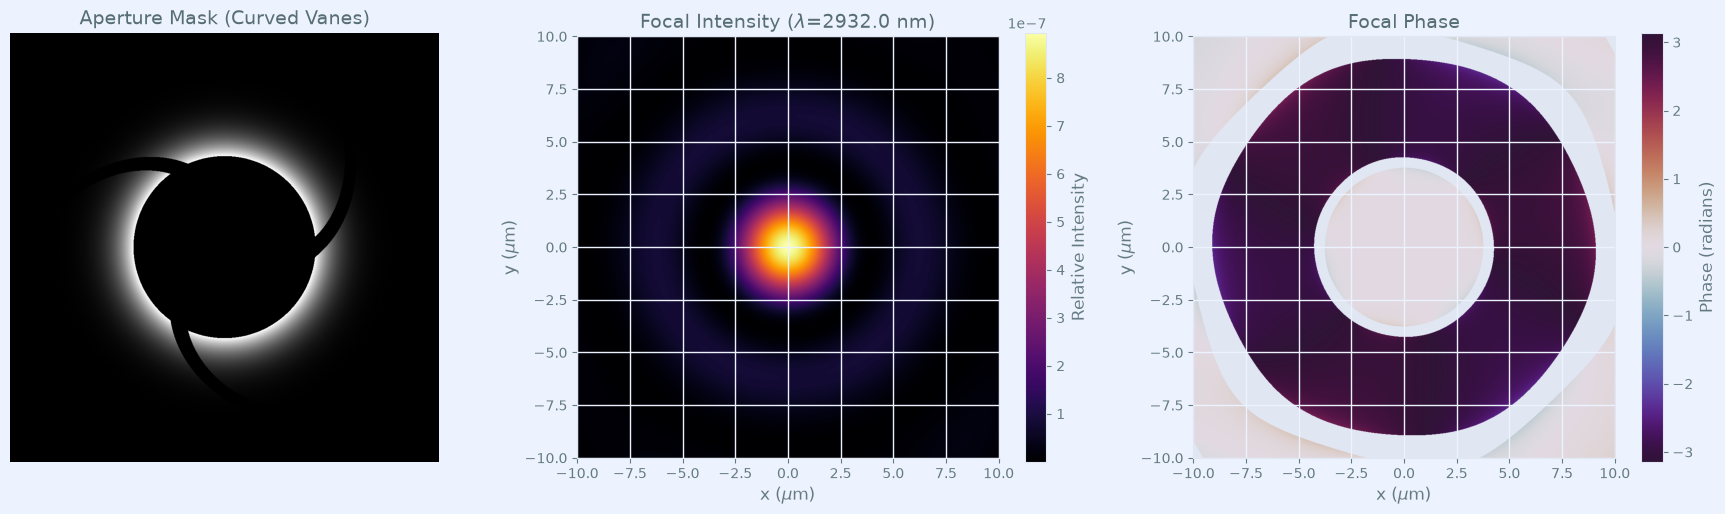

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import poppy
import astropy.units as u

class ThorlabsCurvedVanes(poppy.AnalyticOpticalElement):
    """Custom POPPY aperture modeling the central mirror and 3 curved spider vanes."""
    def __init__(self, pupil_radius, obscuration_radius, vane_width, **kwargs):
        super().__init__(**kwargs)
        self.pupil_radius = pupil_radius.to(u.m).value
        self.obscuration_radius = obscuration_radius.to(u.m).value
        self.vane_width = vane_width.to(u.m).value
        
    def get_transmission(self, wave):
        y, x = self.get_coordinates(wave)
        r = np.hypot(x, y)
        theta = np.arctan2(y, x)
        
        mask = np.ones_like(r)
        
        # 1. Central Mirror Obscuration (18% area)
        mask[r <= self.obscuration_radius] = 0.0
        
        # 2. Outer clear aperture boundary
        mask[r > self.pupil_radius] = 0.0
        
        # 3. Three Curved Vanes
        # We model the sweeping curve as an Archimedean spiral segment.
        # The vanes appear to sweep by roughly 70 degrees (1.2 radians) from center to edge.
        sweep_rate = 1.2 / (self.pupil_radius - self.obscuration_radius) 
        
        for i in range(3):
            theta_start = i * (2 * np.pi / 3) # 120-degree spacing
            
            # The expected angular position of the curved vane at radius r
            theta_vane = theta_start + sweep_rate * (r - self.obscuration_radius)
            
            # Find the angular distance from the pixel to the theoretical vane curve, bounded [-pi, pi]
            d_theta = (theta - theta_vane + np.pi) % (2 * np.pi) - np.pi
            
            # Convert angular distance to approximate physical perpendicular distance
            dist = r * np.abs(d_theta)
            
            # Zero out the transmission mask where pixels fall within the vane width
            vane_region = (r > self.obscuration_radius) & (r <= self.pupil_radius)
            mask[vane_region & (dist < self.vane_width / 2)] = 0.0
            
        return mask

# --- 1. Simulation Parameters ---
wavelength = 2932 * u.nm 
beam_waist = 1.0 * u.mm   # 2 mm diameter Gaussian spot

# Updated Objective Specs
focal_length = 5.0 * u.mm
pupil_radius = (5.1 / 2) * u.mm
obscuration_radius = pupil_radius * np.sqrt(0.18) # 1.082 mm
vane_width = 0.24 * u.mm 

# --- 2. Build the Optical System ---
osys = poppy.OpticalSystem(pupil_diameter=2*pupil_radius, npix=1024)

# Incoming Gaussian Beam
osys.add_pupil(poppy.GaussianAperture(w=beam_waist, name='Input Gaussian Beam'))

# Custom LMM40X Aperture Mask (Mirror + Curved Vanes)
osys.add_pupil(ThorlabsCurvedVanes(pupil_radius=pupil_radius, 
                                   obscuration_radius=obscuration_radius, 
                                   vane_width=vane_width,
                                   name='LMM40X-P01 Mask'))

# --- 3. Define the Focal Plane Detector ---
desired_fov_um = 20.0
npix_detector = 512
desired_pixel_um = desired_fov_um / npix_detector

# Convert micrometers to arcseconds for POPPy's MFT detector
pixel_scale_rad = (desired_pixel_um * 1e-6) / focal_length.to(u.m).value
pixel_scale_arcsec = pixel_scale_rad * (180.0 / np.pi) * 3600.0 * (u.arcsec / u.pixel)

osys.add_detector(pixelscale=pixel_scale_arcsec, fov_pixels=npix_detector, name='Focal Plane')

# --- 4. Run the Simulation ---
psf, waves = osys.calc_psf(wavelength=wavelength, return_intermediates=True, display_intermediates=False)
focal_wave = waves[-1]

intensity = focal_wave.intensity
phase = focal_wave.phase
extent_um = desired_fov_um
extent = [-extent_um/2, extent_um/2, -extent_um/2, extent_um/2]

# --- 5. Plotting ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: The Input Mask (To verify the curved vanes are drawn correctly)
mask_image = waves[1].intensity
axes[0].imshow(mask_image, cmap='gray', origin='lower')
axes[0].set_title('Aperture Mask (Curved Vanes)', fontsize=14)
axes[0].axis('off')

# Plot 2: Intensity
im1 = axes[1].imshow(intensity, extent=extent, cmap='inferno', origin='lower')
axes[1].set_title(f'Focal Intensity ($\lambda$={wavelength.value} nm)', fontsize=14)
axes[1].set_xlabel(r'x ($\\mu$m)')
axes[1].set_ylabel(r'y ($\\mu$m)')
fig.colorbar(im1, ax=axes[1], label='Relative Intensity')

# Plot 3: Phase
# Mask out areas with near-zero intensity to prevent phase noise from dominating the plot
phase_mask = intensity > (intensity.max() * 0.005)
masked_phase = np.ma.masked_where(~phase_mask, phase)

im2 = axes[2].imshow(masked_phase, extent=extent, cmap='twilight_shifted', origin='lower')
axes[2].set_title('Focal Phase', fontsize=14)
axes[2].set_xlabel(r'x ($\\mu$m)')
axes[2].set_ylabel(r'y ($\\mu$m)')
fig.colorbar(im2, ax=axes[2], label='Phase (radians)')

plt.tight_layout()
plt.show()